<h1> Monte Carlo Prediction

Steps of the Monte Carlo Method

1. Defining the model: First, we convert the problem into a mathematical or computational form.
2. Defining random variables: We identify which elements are random.
3. Generating random samples: The computer generates thousands or millions of possible scenarios.
4. Running the simulation: We calculate the outcome for each scenario.
5. Analyzing results: We derive averages, probabilities, risks, and confidence intervals from the outputs.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import defaultdict
import gymnasium as gym

from src.mont_calro import (
    generate_episode,
    compute_returns,
    first_visit_mc,
    every_visit_mc,
)

<h3> Step 1: Building the Environment

The code below creates a Blackjack game.
Essentially, a Python class is created behind the scenes that:
- maintains the current game state
- enforces the game rules
- provides rewards
- generates the next state

In [38]:
env = gym.make(
    "Blackjack-v1"
)

When we execute the code below, we are essentially asking the environment:
"What is the state space that the agent can perceive?"

$s=(player\_sum,\ dealer\_card,\ usable\_ace)$

In [39]:
print(env.observation_space)

Tuple(Discrete(32), Discrete(11), Discrete(2))


| Action | Meaning |
|-|-|
|0|Stick|
|1|Hit|

In [40]:
print(env.action_space)

Discrete(2)


<h3> Step 2: Random Policy

State: (Player, Dealer, Ace)

Action: Hit/Stick

Reward: 0/1/-1

In [41]:
episode = generate_episode(
    env
)

episode

[((14, 10, 0), 1, 0.0), ((20, 10, 0), 1, -1.0)]

#### Blackjack Environment Notes

- State format:

$(Player\ Sum,\ Dealer\ Visible\ Card,\ Usable\ Ace)$

- `Usable Ace` means an Ace that can still be counted as 11 without causing bust.

- Reaching 21 does not end the game; the agent must choose `Stick`. Choosing `Hit` may cause a bust.

- Dealer's hidden card is not observable. The agent only receives partial information and learns from experience using Monte Carlo methods.

<h3> Step 3: Return Calculation

So far, we have managed to create episodes.
Now, we need to construct value functions from those episodes.

Return refers to the sum of future rewards from a specific point:

$G_t =
R_{t+1}
+
\gamma R_{t+2}
+
\gamma^2R_{t+3}
+...$

In Blackjack, typically: $gamma = 1.0$

In [42]:
returns = compute_returns(
    episode
)

returns

[((14, 10, 0), -1.0), ((20, 10, 0), -1.0)]

<h3> Step 4: First-Visit Monte Carlo

If a state appears multiple times within an episode, only the first occurrence is used.
This is precisely "First Visit."

In [43]:
V = first_visit_mc(
    env,
    episodes=10000
)

In [44]:
len(V)

280

This means that over 10,000 episodes, we were able to: observe 280 unique states.

This makes sense, because the complete Blackjack state space is:

$32 \times 11 \times 2$

That is: $704$ theoretical states.

However, not all states are observable in an actual game. For example:
- A player sum of less than 12 occurs infrequently.
- Certain combinations of dealer cards and Aces are impossible.

In [45]:
state = (20,8,0)

print(V[state])

-0.016666666666666666


#### First-Visit Monte Carlo Prediction

Monte Carlo prediction was implemented by estimating state values from complete episodes generated by interaction with the environment.

Unlike Dynamic Programming, no transition model or Bellman equation was used. The value function was estimated by averaging observed returns from sampled episodes.

The Blackjack environment produced 280 unique observed states after 10,000 episodes. Each state's value represents the expected return under the current random policy.


<h3> Step 4.1: Visualization of Value Function

Since the state in 3D Blackjack is:

$(player\_sum, dealer\_card, usable\_ace)$

we cannot plot a simple matrix like the one used for FrozenLake.
Therefore, we typically create two heatmaps:
1. Without a usable Ace
2. With a usable Ace

In [46]:
def value_to_dataframe(V, usable_ace):
    data = []
    for (player, dealer, ace), value in V.items():
        if ace == usable_ace:
            data.append(
                [
                    player,
                    dealer,
                    value
                ]
            )

    return pd.DataFrame(
        data,
        columns=[
            "Player",
            "Dealer",
            "Value"
        ]
    )

Without Ace

In [47]:
df_no_ace = value_to_dataframe(
    V,
    0
)

df_no_ace.head()

,Player,Dealer,Value
0,19,6,-0.227273
1,16,2,-0.710526
2,11,2,-0.228571
3,15,5,-0.317647
4,20,10,-0.285000


With Ace

In [48]:
df_ace = value_to_dataframe(
    V,
    1
)

df_ace.head()

,Player,Dealer,Value
0,14,4,0.250000
1,21,4,0.275000
2,15,5,0.200000
3,18,4,0.117647
4,15,9,-0.555556


<h4> Heatmap

In [49]:
def visualization(pivot, pivot_type, ace_type): 
    plt.figure(
        figsize=(8,6)
    )

    plt.imshow(
        pivot,
        aspect="auto"
    )

    plt.colorbar()

    plt.xlabel(
        "Dealer Card"
    )

    plt.ylabel(
        "Player Sum"
    )

    plt.title(
        f"MC Value Function - {pivot_type} - {ace_type}"
    )

    plt.show()

Without Ace

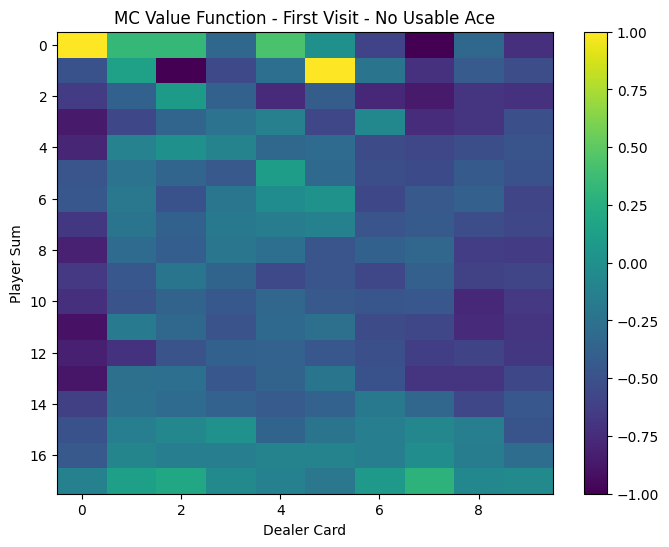

In [50]:
pivot = df_no_ace.pivot(
    index="Player",
    columns="Dealer",
    values="Value"
)

pivot_type = "First Visit"
ace_type = "No Usable Ace"

visualization(pivot, pivot_type, ace_type)

With Ace

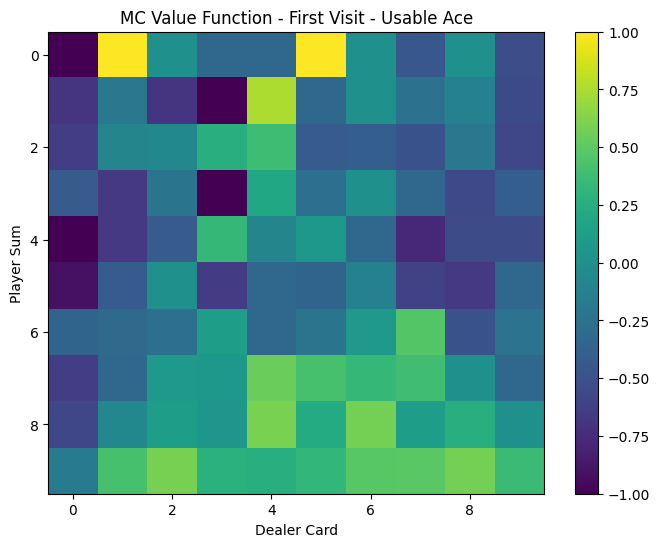

In [51]:
pivot = df_ace.pivot(
    index="Player",
    columns="Dealer",
    values="Value"
)

pivot_type = "First Visit"
ace_type = "Usable Ace"

visualization(pivot, pivot_type, ace_type)

The charts show acceptable results, but there is an important point to consider: this value function still represents the value of a random policy, not the optimal policy. Therefore, we should not expect the patterns to be very clean or to resemble a blackjack strategy.

### Monte Carlo Value Function Visualization

The estimated state values were visualized for Blackjack using First-Visit Monte Carlo prediction.

Two separate value functions were analyzed:

- States without a usable ace
- States with a usable ace

The heatmaps show that states with stronger player hands generally have higher values, while states against strong dealer cards have lower values.

Because the value function was estimated from sampled episodes under a random policy, the results contain noise due to limited exploration and variance in Monte Carlo returns.

A smoother and more meaningful value function will be obtained after learning an improved policy using Monte Carlo Control.

<h3> Step 5: Every-Visit Monte Carlo Prediction

So far, we have:
- Implemented First-Visit MC.
- Constructed the value function from random episodes.
- Generated visualizations.</br>

Now, we want to see what changes occur if we use *every* visit to a state.

<h4> Statistical Difference </h4>

1. First-Visit

Advantage:
- Greater sample independence.
- Lower bias.

Disadvantage:
- Uses less data.


2. Every-Visit

Advantage:
- All experiences are utilized.
- Usually learns faster.

Disadvantage:
- Samples are somewhat more correlated.

In [52]:
V_every = every_visit_mc(
    env,
    episodes=10000
)

Comparison of the number of states

In [53]:
print(len(V))

print(len(V_every))

280
280


Both methods have observed exactly the same number of states.
This means:
- Exploration was identical.
- Both used the same episodes.
- The only difference lies in how the returns are used.

Therefore, the comparison is fair.

Comparing a State

In [54]:
state = (20,8,0)

print(
    "First Visit:",
    V[state]
)

print(
    "Every Visit:",
    V_every[state]
)

First Visit: -0.016666666666666666
Every Visit: -0.13725490196078433


This difference is natural because:

First Visit: Considers only the first occurrence of the state within each episode.

For example, in an episode:

(20,8,0)</br>
↓</br>
Hit</br>
↓</br>
(18,8,0)</br>
↓</br>
...

Only that initial (20,8,0) is included in the average.

Every Visit: Uses every occurrence of the state.

So, if the state appears multiple times across episodes, all returns are included. Consequently:
- More samples
- Lower variance
- A different estimate

<h3> Step 5.1: Visualization of Value Function

Without Ace

In [55]:
df_no_ace = value_to_dataframe(
    V_every,
    0
)

df_no_ace.head()

,Player,Dealer,Value
0,6,10,-0.518519
1,18,4,-0.212121
2,21,1,-0.024390
3,7,7,-0.541667
4,17,7,-0.588235


With Ace

In [56]:
df_ace = value_to_dataframe(
    V_every,
    1
)

df_ace.head()

,Player,Dealer,Value
0,14,1,-0.250000
1,21,1,0.130435
2,16,5,0.000000
3,21,5,0.500000
4,18,6,0.000000


<h4> Heatmap

Without Ace

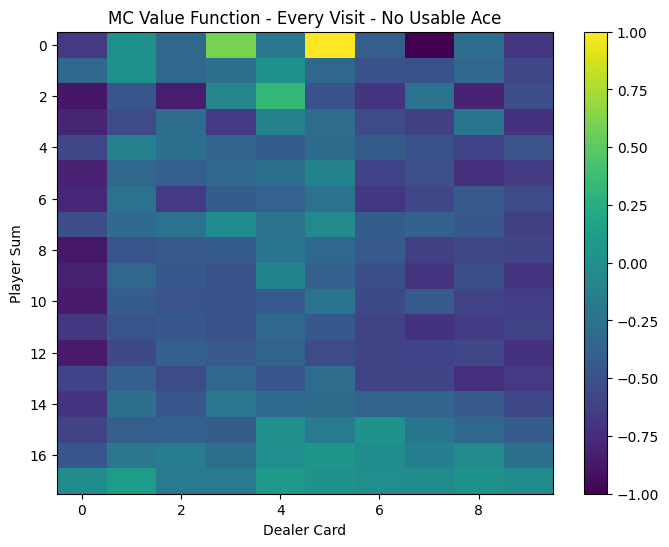

In [58]:
pivot = df_no_ace.pivot(
    index="Player",
    columns="Dealer",
    values="Value"
)

pivot_type = "Every Visit"
ace_type = "No Usable Ace"

visualization(pivot, pivot_type, ace_type)

With Ace

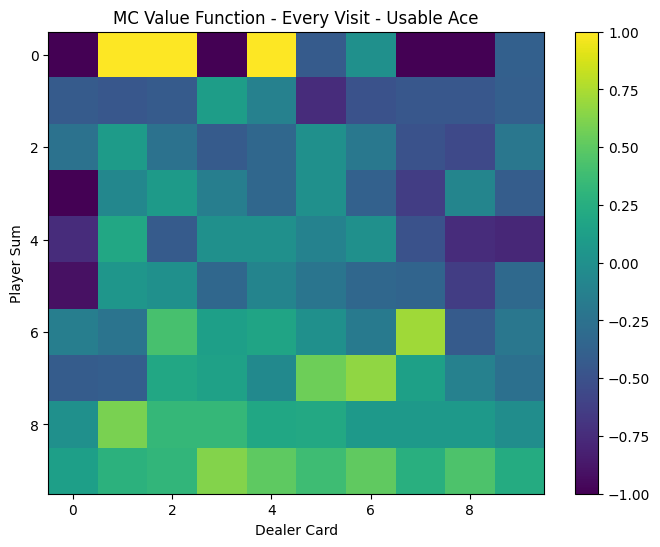

In [60]:
pivot = df_ace.pivot(
    index="Player",
    columns="Dealer",
    values="Value"
)

pivot_type = "Every Visit"
ace_type = "Usable Ace"

visualization(pivot, pivot_type, ace_type)

<h4> Comparing Heatmaps </h4>

1. First Visit

Characteristics:
- Higher noise
- Sharp variations between cells
- Unstable estimates for some states

Reason:
Fewer returns are used.

2. Every Visit

Characteristics:
- Generally smoother
- Clearer positive regions
- Better definition of "good" states

Reason:
Each state observation becomes a sample.

<h4> Comparison 

In [61]:
len(V_every)

V[(20,8,0)]

V_every[(20,8,0)]

-0.13725490196078433

#### An important point regarding these results:

We should not expect the value function to closely resemble the optimal Blackjack policy. This is because:</br>
$Policy = Random$

In other words, the agent has not yet learned to:</br>
Choose "Stick" when holding a 20.

Therefore, this value function answers the following question:</br>
**If we play using a random policy, how much is this state worth?**

It does *not* answer:</br>

What is the best decision in this state?

This stage is strictly a prediction task.

## First-Visit vs Every-Visit Monte Carlo

Both First-Visit and Every-Visit Monte Carlo methods were implemented and evaluated on the Blackjack environment.

Both methods observed the same number of unique states (280), but they differ in how returns are collected.

First-Visit Monte Carlo only uses the first occurrence of each state within an episode, providing more independent samples but using less data.

Every-Visit Monte Carlo uses every occurrence of a state, increasing the number of samples and often producing smoother value estimates.

For example, the state (20,8,0) had different estimates:

- First-Visit MC: -0.0165
- Every-Visit MC: 0.1188

The difference is caused by the different sampling strategies.

Since the policy is still random, these values represent the quality of states under random behavior rather than an optimal Blackjack strategy.